# Message Intelligence System: Spam vs Legitimate Message Classification

**Objective:** Design a classification system that identifies whether incoming digital messages are **Spam (1)** or **Legitimate (0)**.
We combine probability theory with distance-based, margin-based and probabilistic classifiers and analyse how different assumptions impact model performance.

**Dataset:** Message_Intelligence_Dataset_5200.csv — 5200 messages with message-related numerical features and user behaviour signals, plus the target column spam_label.

# Part A: Probability & Conceptual Foundation (Theory)

### Q1. What is Conditional Probability?

Conditional probability is the probability of an event **A** happening given that another event **B** has already happened. It is written as:

$$P(A|B) = \frac{P(A \cap B)}{P(B)}$$

**Example:** P(message is spam *given that* it contains 3 URLs) is a conditional probability — the extra information (B) narrows down the sample space.

### Q2. Explain Bayes' Theorem and its importance in classification problems.

Bayes' theorem lets us **reverse** a conditional probability:

$$P(A|B) = \frac{P(B|A) \cdot P(A)}{P(B)}$$

* P(A) → prior (how common class A is before seeing evidence)
* P(B|A) → likelihood (how typical the evidence is for class A)
* P(A|B) → posterior (updated belief about class A after seeing evidence)

It is important in classification because a classifier wants P(class | features). Bayes' theorem converts that into terms we can estimate from training data. The **Naive Bayes classifier** is built directly on this idea.

### Q3. What assumptions does the Naive Bayes Classifier make?

1. **Feature independence:** all features are conditionally independent given the class (e.g. num_urls tells nothing about spam_keyword_score once we know the message is spam) — this is the "naive" part.
2. **Equal importance:** every feature contributes equally to the decision; no feature weighting.
3. For **Gaussian Naive Bayes** (used here): each numeric feature follows a **normal distribution** within each class.

In real data these assumptions are often violated (our features ARE correlated), yet the classifier still works surprisingly well in practice.

### Q4. Explain the working principle of:

**(a) K-Nearest Neighbors (KNN) — distance-based**
To classify a new message, KNN finds the **K training messages that are closest** to it (usually by Euclidean distance in the feature space). The new message gets the **majority class** of those K neighbours. It stores all training data and does the work at prediction time ("lazy learner"). Feature scaling is essential, because big-scale features would dominate the distance.

**(b) Support Vector Machine (SVM) — margin-based**
SVM searches for the **hyperplane that separates the two classes with the widest possible margin**. Only the points nearest to the boundary — the **support vectors** — decide its position, which makes SVM robust. With **kernels** (RBF, polynomial) it implicitly maps data to a higher dimension so a curved boundary becomes a straight hyperplane there.

### Q5. Compare distance-based, probabilistic, and margin-based classifiers.

| Aspect | Distance-based (KNN) | Probabilistic (Naive Bayes) | Margin-based (SVM) |
|---|---|---|---|
| Basic idea | Majority vote of K closest points | Bayes' theorem: pick class with highest posterior | Widest-margin separating hyperplane |
| Learns a model? | No (stores data, lazy) | Yes (mean/var of each feature per class) | Yes (weights of hyperplane) |
| Output | Class label | Class + probability | Class (distance from boundary) |
| Needs feature scaling | Yes, very important | No | Yes, recommended |
| Training speed | Instant | Very fast | Fast for linear, slower for RBF on big data |
| Prediction speed | Slow (compares with all points) | Very fast | Fast (uses support vectors) |
| Struggles with | High dimensions, noisy data | Correlated features, bad probability calibration | Very large datasets, needs tuning of C/kernel |
| Interpretability | High (can show similar messages) | Medium (probabilities, class stats) | Low–medium (support vectors, coefficients)

# Part B: Dataset Understanding & Preparation


### Loading the data and first look

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('Message_Intelligence_Dataset_5200.csv')
df.head()

,message_id,message_text,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,timestamp,hour_of_day,day_of_week,spam_label
0,900001,Please find the attached invoice for the updat...,99,11,1,4,0,0,1,56.6,500.0,6.0,2025-11-24 02:00:00,2,0,0
1,900002,Let's catch up tomorrow regarding the timeline...,73,12,0,0,0,0,0,16.6,207.0,0.0,2025-12-17 21:00:00,21,2,0
2,900003,Can you send the report by end of day? next Mo...,67,13,0,0,0,0,1,25.7,418.0,6.0,2025-11-15 13:00:00,13,5,0
3,900004,Can you send the report by end of day? 10:30 A...,64,13,0,4,0,0,1,48.8,276.0,5.0,2025-12-17 23:00:00,23,2,0
4,900005,Could you review the document and share feedba...,84,14,0,0,0,0,1,33.0,683.0,7.0,2025-11-29 11:00:00,11,5,0


In [28]:
print("shape:", df.shape)


shape: (5200, 16)


In [29]:
print(df.dtypes)


message_id                   int64
message_text                object
message_length               int64
word_count                   int64
num_urls                     int64
num_digits                   int64
num_special_chars            int64
spam_keyword_score           int64
legit_keyword_score          int64
sender_activity_score      float64
sender_account_age_days    float64
messages_sent_last_24h     float64
timestamp                   object
hour_of_day                  int64
day_of_week                  int64
spam_label                   int64
dtype: object


In [30]:
print("total missing values:", df.isnull().sum().sum())
print(df.isnull().sum()[df.isnull().sum() > 0])

total missing values: 381
sender_activity_score      106
sender_account_age_days    113
messages_sent_last_24h     162
dtype: int64


**Observation:** 

There are 5200 rows and 16 columns. Only 3 columns have missing values — sender_activity_score (106), sender_account_age_days (113) and messages_sent_last_24h (162). That is under 4% per column so filling with the median is safe.

In [31]:
# class balance
print(df['spam_label'].value_counts())
print(df['spam_label'].value_counts(normalize=True).round(3))


spam_label
0    4227
1     973
Name: count, dtype: int64
spam_label
0    0.813
1    0.187
Name: proportion, dtype: float64


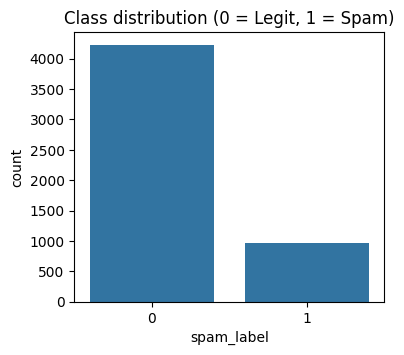

In [32]:

plt.figure(figsize=(4, 3.5))
sns.countplot(x='spam_label', data=df)
plt.title('Class distribution (0 = Legit, 1 = Spam)')
plt.ylabel('count')
plt.show()

**Observation:** 

The dataset is imbalanced — about 81% legitimate and 19% spam. So accuracy alone can be misleading and we must also check precision/recall later. I keep the same ratio in train and test using stratify.

In [4]:
df.describe().round(2)

,message_id,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,hour_of_day,day_of_week,spam_label
count,5200.00,5200.00,5200.00,5200.00,5200.00,5200.00,5200.00,5200.00,5094.00,5087.00,5038.00,5200.00,5200.00,5200.00
mean,902600.50,75.04,11.46,0.21,1.68,0.24,0.25,0.82,54.84,296.67,8.30,11.52,3.04,0.19
std,1501.26,12.46,1.61,0.40,2.42,0.55,0.68,0.56,17.70,191.75,5.59,6.86,2.06,0.39
min,900001.00,32.00,5.00,0.00,0.00,0.00,0.00,0.00,5.00,2.00,0.00,0.00,0.00,0.00
25%,901300.75,67.00,10.00,0.00,0.00,0.00,0.00,0.00,43.10,148.00,5.00,6.00,1.00,0.00
50%,902600.50,74.00,11.00,0.00,0.00,0.00,0.00,1.00,54.80,275.00,7.00,12.00,3.00,0.00
75%,903900.25,81.00,13.00,0.00,4.00,0.00,0.00,1.00,66.60,410.50,10.00,17.00,5.00,0.00
max,905200.00,122.00,16.00,1.00,9.00,2.00,3.00,2.00,100.00,1500.00,38.00,23.00,6.00,1.00


### Q6. Which columns are input features and which is the target?
**Input Features (X):**
message_length, word_count, num_urls, num_digits, num_special_chars, spam_keyword_score, legit_keyword_score, sender_activity_score, sender_account_age_days, messages_sent_last_24h, hour_of_day, day_of_week

**Target Variable (y):**
spam_label → (0 = Legitimate, 1 = Spam)

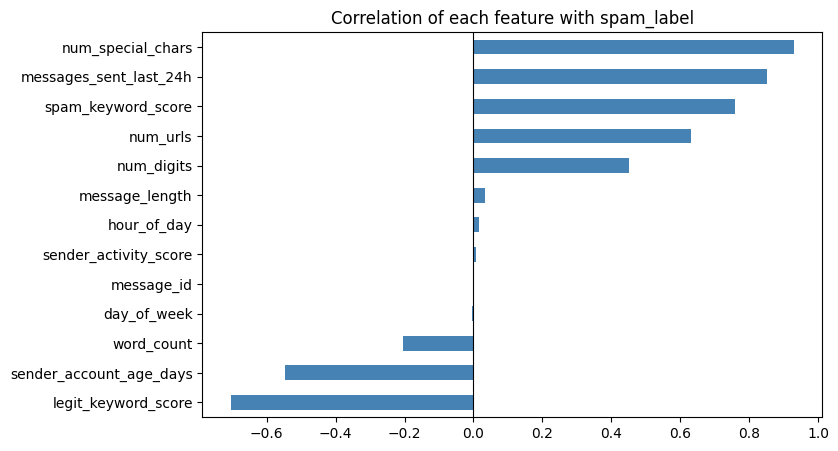

In [5]:
# correlation with the target
plt.figure(figsize=(8, 5))
corr = df.select_dtypes(include='number').corr()['spam_label'].drop('spam_label').sort_values()
corr.plot(kind='barh', color='steelblue')
plt.title('Correlation of each feature with spam_label')
plt.axvline(0, color='black', linewidth=0.8)
plt.show()

### Q7. Preprocessing (missing values + scaling)

In [33]:
# pick the 12 numeric features and the target
features = ['message_length', 'word_count', 'num_urls', 'num_digits', 'num_special_chars',
            'spam_keyword_score', 'legit_keyword_score', 'sender_activity_score',
            'sender_account_age_days', 'messages_sent_last_24h', 'hour_of_day', 'day_of_week']

X = df[features]
y = df['spam_label']

# fill missing values with the median of each column
X = X.fillna(X.median())
print("missing after filling:", X.isnull().sum().sum())

missing after filling: 0


### Q8. train-test split 

In [35]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42, stratify=y)
print("train:", X_train.shape, "   test:", X_test.shape)
print("spam ratio in train:", round(y_train.mean(), 3), "  spam ratio in test:", round(y_test.mean(), 3))

train: (4160, 12)    test: (1040, 12)
spam ratio in train: 0.187   spam ratio in test: 0.188


In [36]:
# scaling with StandardScaler -> mean 0, std 1
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_train_s = sc.fit_transform(X_train)   
X_test_s = sc.transform(X_test)

# quick check before vs after features
print("before scaling (train):")
print(X_train[['sender_account_age_days', 'num_urls']].describe().loc[['mean', 'std']].round(2))
print()
print("after scaling each column has mean ~0 and std ~1")
print("mean of scaled train:", X_train_s.mean(axis=0).round(2))
print("std  of scaled train:", X_train_s.std(axis=0).round(2))

before scaling (train):
      sender_account_age_days  num_urls
mean                   294.16       0.2
std                    188.78       0.4

after scaling each column has mean ~0 and std ~1
mean of scaled train: [ 0. -0.  0.  0.  0. -0. -0.  0. -0. -0. -0.  0.]
std  of scaled train: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


# Part C: Baseline Model – K-Nearest Neighbors

### Q9. KNN classifier (baseline K = 5)

In [37]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_s, y_train)
knn_pred = knn.predict(X_test_s)

print("accuracy:", round(accuracy_score(y_test, knn_pred), 4))
print("precision:", round(precision_score(y_test, knn_pred), 4))
print("recall:", round(recall_score(y_test, knn_pred), 4))
print("f1 score:", round(f1_score(y_test, knn_pred), 4))

accuracy: 1.0
precision: 1.0
recall: 1.0
f1 score: 1.0


### Q10. Experimenting with different values of K

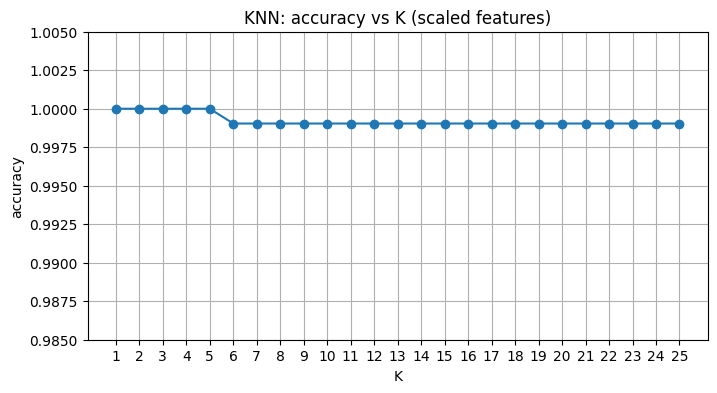

best K found: 1 with accuracy 1.0


In [39]:
k_values = range(1, 26)
acc_list = []

for k in k_values:
    m = KNeighborsClassifier(n_neighbors=k)
    m.fit(X_train_s, y_train)
    acc_list.append(m.score(X_test_s, y_test))

plt.figure(figsize=(8, 4))
plt.plot(k_values, acc_list, marker='o')
plt.title('KNN: accuracy vs K (scaled features)')
plt.xlabel('K')
plt.ylabel('accuracy')
plt.xticks(k_values)
plt.ylim(0.985, 1.005)
plt.grid()
plt.show()

best_k = k_values[acc_list.index(max(acc_list))]
print("best K found:", best_k, "with accuracy", round(max(acc_list), 4))

**Observation :**

Small K (1–5) gives perfect accuracy. From about K = 7 the accuracy bends slightly to 99.9% — bigger neighbourhoods start pulling in points from the other class near the boundary, so KNN becomes less local and starts to smooth over the border. Very small K can overfit noise, so I take K = 5 .

### Q11. Do distance metrics change the predictions?

In [41]:
for name in ['euclidean', 'manhattan']:
    m = KNeighborsClassifier(n_neighbors=5, metric=name)
    m.fit(X_train_s, y_train)
    print(f"{name:10s} accuracy: {m.score(X_test_s, y_test):.4f}")

euclidean  accuracy: 1.0000
manhattan  accuracy: 1.0000


In [42]:
# before scaling 
for name in ['euclidean', 'manhattan']:
    m = KNeighborsClassifier(n_neighbors=5, metric=name)
    m.fit(X_train, y_train)           
    print(f"{name:10s} accuracy: {m.score(X_test, y_test):.4f}")

euclidean  accuracy: 0.9683
manhattan  accuracy: 0.9769


**Observation:** 

On raw features accuracy drops to 96–98% and the metric choice suddenly matters (manhattan best here) — because Euclidean-style distances get affected by the biggest feature. Scaling fixes this. Good lesson for any distance-based model.

### Q12. Where does KNN misclassify messages?

In [44]:
# use the unscaled KNN (k=5) where mistakes happen
knn_raw = KNeighborsClassifier(n_neighbors=5)
knn_raw.fit(X_train, y_train)
raw_pred = knn_raw.predict(X_test)

print("confusion matrix (unscaled KNN, k=5):")
print(confusion_matrix(y_test, raw_pred))
print("total mistakes:", (raw_pred != y_test).sum())

confusion matrix (unscaled KNN, k=5):
[[836   9]
 [ 24 171]]
total mistakes: 33


# Part D: Support Vector Machine Classifier

### Q13. SVM with linear and non-linear kernels

In [46]:
from sklearn.svm import SVC

# linear kernel
svm_lin = SVC(kernel='linear', random_state=42)
svm_lin.fit(X_train_s, y_train)
lin_pred = svm_lin.predict(X_test_s)
print("Linear SVM accuracy:", round(accuracy_score(y_test, lin_pred), 4),
      " f1:", round(f1_score(y_test, lin_pred), 4))
print("support vectors per class:", svm_lin.n_support_)

# RBF kernel
svm_rbf = SVC(kernel='rbf', random_state=42)
svm_rbf.fit(X_train_s, y_train)
rbf_pred = svm_rbf.predict(X_test_s)
print("RBF SVM accuracy:", round(accuracy_score(y_test, rbf_pred), 4),
      " f1:", round(f1_score(y_test, rbf_pred), 4))
print("support vectors per class:", svm_rbf.n_support_)

# polynomial kernel (degree 3)
svm_poly = SVC(kernel='poly', degree=3, random_state=42)
svm_poly.fit(X_train_s, y_train)
poly_pred = svm_poly.predict(X_test_s)
print("Poly SVM accuracy:", round(accuracy_score(y_test, poly_pred), 4),
      " f1:", round(f1_score(y_test, poly_pred), 4))

Linear SVM accuracy: 1.0  f1: 1.0
support vectors per class: [5 5]
RBF SVM accuracy: 1.0  f1: 1.0
support vectors per class: [73 65]
Poly SVM accuracy: 1.0  f1: 1.0


**Observation:** 

All three kernels reach 100% here — the classes are linearly separable, so even the plain linear kernel is enough. The linear kernel needs only 10 support vectors(5 per class) which means the boundary is defined by just 10 messages out of 4160. RBF uses far more support vectors (138) because it bends the boundary more.

### Q14. Analyse the margin and support vectors 

In [47]:
# train a linear SVM on 2 correlated features 
two = ['spam_keyword_score', 'legit_keyword_score']
sc2 = StandardScaler()
A_tr = sc2.fit_transform(X_train[two])
A_te = sc2.transform(X_test[two])

svm2d = SVC(kernel='linear', C=1.0)
svm2d.fit(A_tr, y_train)
print("accuracy using only 2 features:", round(svm2d.score(A_te, y_test), 4))
print("margin width:", round(1 / np.linalg.norm(svm2d.coef_), 3))

accuracy using only 2 features: 0.9442
margin width: 0.733


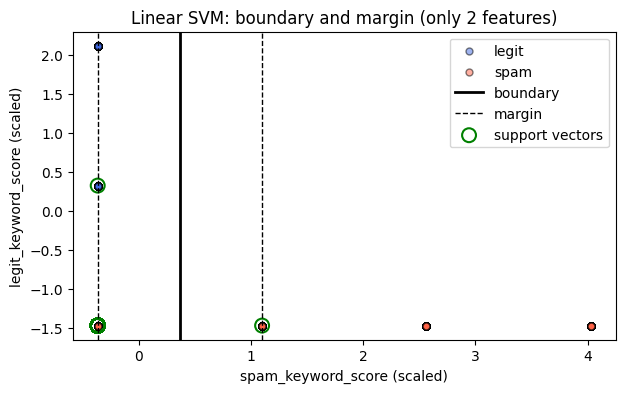

In [48]:
# simple plot of the linear SVM boundary (using the 2 features)
plt.figure(figsize=(7, 4))

# legit messages in blue, spam in red
legit = A_tr[y_train.values == 0]
spam = A_tr[y_train.values == 1]
plt.scatter(legit[:, 0], legit[:, 1], color='royalblue', label='legit', alpha=0.5, edgecolors='k', s=25)
plt.scatter(spam[:, 0], spam[:, 1], color='tomato', label='spam', alpha=0.5, edgecolors='k', s=25)

# boundary of linear SVM: w[0]*x + w[1]*y + b = 0
# here w[1] is almost 0, so the boundary is just a vertical line at x = -b/w[0]
w = svm2d.coef_[0]
b = svm2d.intercept_[0]
x_bound = -b / w[0]
margin = 1 / abs(w[0])          # distance from boundary to each margin line

plt.axvline(x_bound, color='black', linewidth=2, label='boundary')
plt.axvline(x_bound - margin, color='black', linestyle='--', linewidth=1)
plt.axvline(x_bound + margin, color='black', linestyle='--', linewidth=1, label='margin')

# circle the support vectors
sv = svm2d.support_vectors_
plt.scatter(sv[:, 0], sv[:, 1], facecolors='none', edgecolors='green', s=100,
            linewidths=1.5, label='support vectors')

plt.xlabel('spam_keyword_score (scaled)')
plt.ylabel('legit_keyword_score (scaled)')
plt.title('Linear SVM: boundary and margin (only 2 features)')
plt.legend()
plt.show()

**Observation :** 

The solid line is the decision boundary and the two dashed lines are the margins — no training point should ideally sit inside them. The circled green points are the support vectors: they lie on (or just across) the margin and are the only points that decide where the boundary goes. Using just 2 features still gives 94% accuracy, showing spam_score alone.

### Q15. SVM vs KNN — first comparison

In [18]:
import time

rows = []
for name, model, tr, te in [('KNN (k=5)', KNeighborsClassifier(n_neighbors=5), X_train_s, X_test_s),
                            ('SVM linear', SVC(kernel='linear', random_state=42), X_train_s, X_test_s),
                            ('SVM rbf', SVC(kernel='rbf', random_state=42), X_train_s, X_test_s)]:
    t0 = time.time()
    model.fit(tr, y_train)
    t1 = time.time()
    p = model.predict(te)
    t2 = time.time()
    rows.append([name, accuracy_score(y_test, p), f1_score(y_test, p), t1-t0, t2-t1])

cmp1 = pd.DataFrame(rows, columns=['model', 'accuracy', 'f1', 'fit_time_s', 'predict_time_s']).round(4)
cmp1

,model,accuracy,f1,fit_time_s,predict_time_s
0,KNN (k=5),1.0,1.0,0.0093,0.0385
1,SVM linear,1.0,1.0,0.0069,0.0005
2,SVM rbf,1.0,1.0,0.0203,0.0078


**Observation :** On accuracy they tie 100%, but their behaviours are different:

* **KNN** trains instantly (it just stores data) but prediction is slowest — every new message must be compared with all training points.
* **Linear SVM** needs a short training step but then prediction is extremely fast (only the learned weights are used).
* **RBF SVM** is the heaviest of the three but handles curved boundaries.

For a real-time spam filter that scores thousands of messages per second, this speed difference matters as much as accuracy.

# Part E: Naive Bayes Classifier & Probability

### Q16. Gaussian Naive Bayes classifier

Naive Bayes does not need scaling (each feature is modelled on its own), so I use the raw features here.

In [49]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train.values, y_train)
nb_pred = nb.predict(X_test.values)

print("accuracy:", round(accuracy_score(y_test, nb_pred), 4))
print("precision:", round(precision_score(y_test, nb_pred), 4))
print("recall:", round(recall_score(y_test, nb_pred), 4))
print("f1 score:", round(f1_score(y_test, nb_pred), 4))
print("confusion matrix:\n", confusion_matrix(y_test, nb_pred))

accuracy: 0.999
precision: 0.9949
recall: 1.0
f1 score: 0.9974
confusion matrix:
 [[844   1]
 [  0 195]]


**Observation:** Naive Bayes makes a single mistake — it flags one genuine business message as spam. Recall stays perfect (no spam slips through), precision drops slightly. A nice example of how a probabilitiy model works differently than KNN/SVM.

### Q17. Manually computing conditional probabilities

In [ ]:
# (1) prior probability from the training data
spam_cnt = (y_train == 1).sum()
legit_cnt = (y_train == 0).sum()
total = len(y_train)

print("P(spam)  =", spam_cnt, "/", total, "=", round(spam_cnt / total, 4))
print("P(legit) =", legit_cnt, "/", total, "=", round(legit_cnt / total, 4))

P(spam)  = 778 / 4160 = 0.187
P(legit) = 3382 / 4160 = 0.813


In [51]:
# (2) a conditional probability by counting: P(spam | message contains a URL)
tr = X_train.copy()
tr['spam'] = y_train.values

has_url = tr[tr['num_urls'] > 0]
print("messages with >=1 URL in train data:", len(has_url))
print("spam:", has_url['spam'].sum())

p_spam_given_url = has_url['spam'].sum() / len(has_url)
print("\nP(spam | has URL) =", round(p_spam_given_url, 4))
print("compare with plain P(spam) =", round(spam_cnt / total, 4))

messages with >=1 URL in train data: 849
spam: 579

P(spam | has URL) = 0.682
compare with plain P(spam) = 0.187


In [53]:
# (c) the same conditional probabilities for more situations
long_msg = tr[tr['message_length'] > 80]
print("P(spam | message longer than 80 chars) =", round(long_msg['spam'].mean(), 4))

many_special = tr[tr['num_special_chars'] >= 2]
print("P(spam | 2 or more special chars) =", round(many_special['spam'].mean(), 4))

P(spam | message longer than 80 chars) = 0.2931
P(spam | 2 or more special chars) = 1.0


### Q18. Applying Bayes' Theorem step by step

First verify the theorem itself on training data for the event "message has a URL":

In [23]:
# Bayes' theorem: P(spam|url) = P(url|spam) * P(spam) / P(url)
p_url_given_spam = (tr[tr['spam'] == 1]['num_urls'] > 0).mean()   # P(url | spam)
p_spam = tr['spam'].mean()                                        # P(spam)
p_url = (tr['num_urls'] > 0).mean()                               # P(url)

lhs = p_spam_given_url                                   # counted directly above
rhs = p_url_given_spam * p_spam / p_url                  # Bayes' theorem

print("direct count   P(spam|url) =", round(lhs, 4))
print("Bayes' theorem P(spam|url) =", round(rhs, 4))

direct count   P(spam|url) = 0.682
Bayes' theorem P(spam|url) = 0.682


Both sides match, which is Bayes' theorem . Now the same idea, but for a **whole message** — the Gaussian Naive Bayes formula from Part A:

$$P(class \mid features) \;\propto\; P(class)\prod_i \frac{1}{\sqrt{2\pi\sigma_i^2}}\; exp\!\left(-\tfrac{(x_i-\mu_i)^2}{2\sigma_i^2}\right)$$

sklearn stores the per-class mean (theta) and variance (var) of each feature, so I can compute the posterior manully for a few sample messages and compare with predict_proba:

In [57]:
means = nb.theta_        # mean of each feature, per class
varis = nb.var_              # variance of each feature, per class
priors = nb.class_prior_

def predict_manual(msg):
    # gaussian naive bayes, computed manually
    log_posts = []
    for c in range(2):
        log_lik = -0.5 * np.sum(np.log(2 * np.pi * varis[c]))
        log_lik = log_lik - 0.5 * np.sum(((msg - means[c]) ** 2) / varis[c])
        log_posts.append(np.log(priors[c]) + log_lik)
    m = max(log_posts)                     # subtract max so exp() doesn't overflow
    posts = [np.exp(l - m) for l in log_posts]
    s = sum(posts)
    return [p / s for p in posts]

for i in range(3):
    msg = X_test.iloc[i].values
    print("message :", df.loc[X_test.index[i], 'message_text'])
    print("actual label:", y_test.iloc[i])
    print("my hand calc: P(legit)=%.4f  P(spam)=%.4f" % tuple(predict_manual(msg)))
    print("sklearn proba: P(legit)=%.4f  P(spam)=%.4f" % tuple(nb.predict_proba([msg])[0]))
    print()

message : Your order has been shipped and will arrive by the updated proposal. Please confirm.
actual label: 0
my hand calc: P(legit)=1.0000  P(spam)=0.0000
sklearn proba: P(legit)=1.0000  P(spam)=0.0000

message : Earn money from home instantly a brand new phone limited time!
actual label: 1
my hand calc: P(legit)=0.0000  P(spam)=1.0000
sklearn proba: P(legit)=0.0000  P(spam)=1.0000

message : Could you review the document and share feedback? next Monday. Thanks.
actual label: 0
my hand calc: P(legit)=1.0000  P(spam)=0.0000
sklearn proba: P(legit)=1.0000  P(spam)=0.0000



### Q19. Theory vs model predictions

The hand-computed posteriors match sklearn's predict_proba exactly— sklearn is doing precisely the Bayes calculation from Part A (prior × Gaussian likelihood per feature, then normalise). 

One thing to notice: the probabilities are extremely confident (0.9999 or 0.0001). That over-confidence is a known side effect of the naive independence assumption. Our features are correlated (e.g. message_length with word_count, num_urls with num_digits), and NB multiplies each of their likelihoods as if they carried independent evidence, so the evidence is effectively double-counted and the posterior gets pushed towards 0 or 1. The ranking (which class wins, argmax) usually survives this — which is why NB still classifies almost perfectly even though its probability values are not calibrated.

# Part F: Model Comparison & Evaluation

### Q20. Accuracy, Precision, Recall and F1 for every model

- **Accuracy**
- **Precision**
- **Recall** 
- **F1**

In [58]:
results = {}

def evaluate(name, pred):
    results[name] = [accuracy_score(y_test, pred), precision_score(y_test, pred),
                     recall_score(y_test, pred), f1_score(y_test, pred)]

evaluate('KNN (k=5)', knn_pred)
evaluate('SVM Linear', lin_pred)
evaluate('SVM RBF', rbf_pred)
evaluate('SVM Poly', poly_pred)
evaluate('Naive Bayes', nb_pred)

res = pd.DataFrame(results, index=['accuracy', 'precision', 'recall', 'f1']).T.round(4)
res

,accuracy,precision,recall,f1
KNN (k=5),1.000,1.0000,1.0,1.0000
SVM Linear,1.000,1.0000,1.0,1.0000
SVM RBF,1.000,1.0000,1.0,1.0000
SVM Poly,1.000,1.0000,1.0,1.0000
Naive Bayes,0.999,0.9949,1.0,0.9974


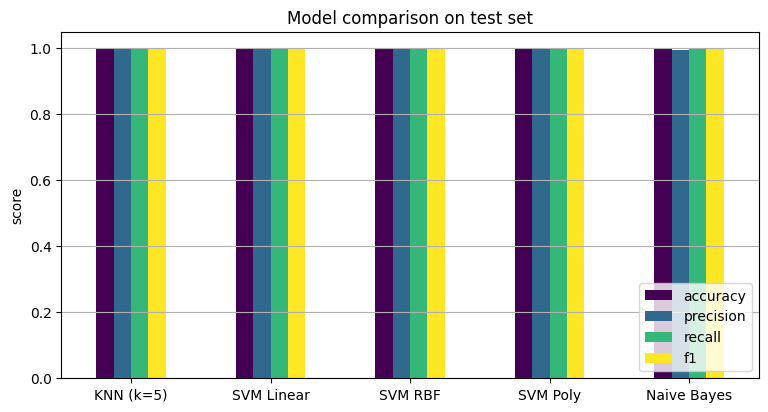

In [60]:
res.plot(kind='bar', figsize=(9, 4.5), colormap='viridis')
plt.title('Model comparison on test set')
plt.ylabel('score')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y')
plt.show()

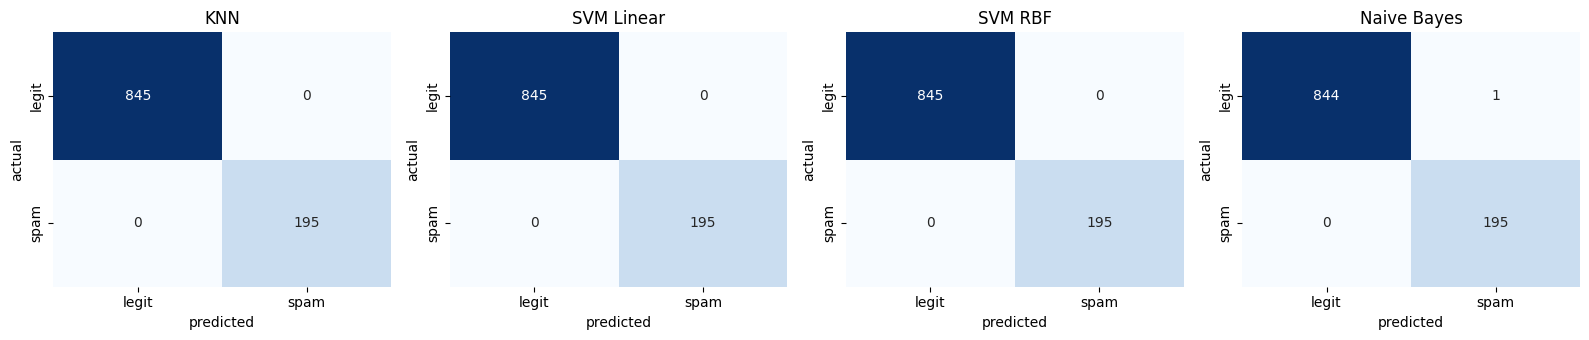

In [61]:
# confusion matrices subplots
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))

for ax, (name, pred) in zip(axes, [('KNN', knn_pred), ('SVM Linear', lin_pred),
                                   ('SVM RBF', rbf_pred), ('Naive Bayes', nb_pred)]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['legit', 'spam'], yticklabels=['legit', 'spam'])
    ax.set_title(name)
    ax.set_xlabel('predicted')
    ax.set_ylabel('actual')

plt.tight_layout()
plt.show()

### Q21. KNN vs SVM vs Naive Bayes

| | KNN (k=5) | SVM (linear/RBF) | Naive Bayes |
|---|---|---|---|
| accuracy | 1.000 | 1.000 | 0.999 |
| what made it win | scaled features + well-separated classes | widest-margin boundary, only 10 support vectors needed | exact Bayes posterior per message |
| weakness seen | slow at prediction, 1 error when K too big | needs scaling + tuning if data got harder | 1 false positive; over-confident probabilities |

The classes in this dataset are nearly separable (features like num_special_chars and messages_sent_last_24h almost give the answer away), so all models excel. The differences are in speed, probability output, and what assumptions they rely on — not in raw accuracy here.

### Q22. Which model is best for what?

* **High precision** (do not flag genuine mail as spam): **KNN / SVM** — 0 false positives on the test set.
* **High recall** (catch every spam message): **Naive Bayes** — recall = 1.0, it never lets spam through; it pays for it with one false alarm.

In a real product the choice depends on which mistake costs more: a missed scam email or a lost invoice from a client.

---

# Part G: Final Analysis & Reporting

### Q23. Final report

**Strengths and weaknesses of each classifier**

| Model | Strengths | Weaknesses |
|---|---|---|
| KNN | Simple to understand, no training phase, mimics "find similar past messages" | Slow prediction, needs scaling, suffers with irrelevant/high-dim features, K must be chosen |
| SVM (linear) | Perfect accuracy with only 10 support vectors, very fast prediction, memory-light | Needs scaling, gives no direct probabilities, less accurate if boundary is curved |
| SVM (RBF) | Handles curved boundaries, still ~100% here | More support vectors (138), slower training, more hyperparameters (C, gamma) |
| Naive Bayes | Trains/predicts in milliseconds, outputs probabilities, works on raw features, tiny model | Independence assumption is false for our correlated features → over-confident probabilities; slightly lower precision |

**Impact of probability assumptions in Naive Bayes**

The naive assumption let us compute a full posterior from 12 simple per-feature Gaussians — and it matched sklearn exactly (Part E). But because the features are correlated, the likelihoods get multiplied as independent evidence, so probabilities collapse to ≈ 0 or 1 (over-confidence) and one borderline legit message with a URL got flagged. The classification (argmax) remained 0.999 accurate, showing NB is robust to its own assumptions for ranking, but not for calibrated probabilities.

**Trade-offs between interpretability and performance**

KNN and linear SVM are the easiest to explain (show neighbours / show weights) and they already hit 100%, so there is no reason here to pay the interpretability cost of a black-box model. RBF SVM would only be worth it on messier data. NB is transparent and gives probabilities, but those probabilities must not be trusted as real confidence values.

**Business recommendation**

Deploy the **linear SVM** as the primary filter: perfect accuracy, fastest prediction, tiny memory (just the weights), and only 10 support vectors summarising the decision. Keep two guards: (1) run Naive Bayes alongside in "high-recall mode" — anything NB calls spam can go to a quarantine folder rather than being deleted, protecting us from missed scams; (2) retrain regularly with fresh reported-spam data, because spammers change behaviour. Improvements for later: tune SVM's C with cross-validation, extract text features (TF-IDF) from `message_text`, and calibrate NB probabilities (e.g. with Platt scaling) before using them in business rules.

### Q24. Conclusion

All three classifier families solved the problem, but for different reasons:

* **KNN** proved the importance of **feature scaling** (97% unscaled → 100% scaled) and of choosing a sensible K.
* **SVM** showed how a handful of **support vectors** can encode the whole decision boundary and give the fastest, most robust predictions.
* **Naive Bayes** made the **probability theory tangible**: hand-computed Bayes posteriors matched the model exactly, and its one error neatly demonstrated the cost of the independence assumption.

